In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

C:\Users\praja\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\praja\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
project_dir = Path(
    r"C:\Users\praja\functional-connectivity\neuroscience_project"
)

results_dir = project_dir / "results"

D = np.load(results_dir / "distance_matrix.npy")
H0 = np.load(results_dir / "persistence_H0.npy")
H1 = np.load(results_dir / "persistence_H1.npy")

milestone8 = pd.read_csv(
    results_dir / "milestone8_threshold_sensitivity.csv"
)

print("Distance matrix:", D.shape)
print("H0:", H0.shape)
print("H1:", H1.shape)
print("Milestone 8:", milestone8.shape)

Distance matrix: (74, 74)
H0: (74, 2)
H1: (18, 2)
Milestone 8: (5, 7)


In [5]:
thresholds = milestone8["threshold"].to_numpy()

print("Network thresholds:")

for threshold in thresholds:
    print(round(float(threshold), 5))

Network thresholds:
0.53945
0.66617
0.79915
0.95421
1.14981


In [7]:
def network_metrics(A):

    n = len(A)

    degree = A.sum(axis=1)

    density = A.sum() / (n * (n - 1))

    A2 = A @ A
    A3 = A2 @ A

    triangles = np.diag(A3) / 2

    possible_triangles = degree * (degree - 1) / 2

    local_clustering = np.divide(
        triangles,
        possible_triangles,
        out=np.zeros(n, dtype=float),
        where=possible_triangles > 0
    )

    distances = np.where(A, 1.0, np.inf)
    np.fill_diagonal(distances, 0)

    for k in range(n):
        distances = np.minimum(
            distances,
            distances[:, k:k+1] + distances[k:k+1, :]
        )

    inverse_distances = np.divide(
        1,
        distances,
        out=np.zeros_like(distances),
        where=np.isfinite(distances) & (distances > 0)
    )

    efficiency = inverse_distances.sum() / (n * (n - 1))

    return {
        "density": float(density),
        "mean_degree": float(degree.mean()),
        "maximum_degree": int(degree.max()),
        "mean_clustering": float(local_clustering.mean()),
        "global_efficiency": float(efficiency)
    }

In [9]:
network_results = []

for threshold in thresholds:

    adjacency = D <= threshold

    np.fill_diagonal(adjacency, False)

    metrics = network_metrics(adjacency)

    metrics["threshold"] = float(threshold)

    network_results.append(metrics)

network_df = pd.DataFrame(network_results)

print(network_df.to_string(index=False))

 density  mean_degree  maximum_degree  mean_clustering  global_efficiency  threshold
0.100333     7.324324              28         0.066325           0.224159   0.539447
0.250278    18.270270              40         0.033328           0.503502   0.666167
0.500185    36.513514              58         0.016658           0.700882   0.799151
0.750093    54.756757              69         0.000441           0.835061   0.954212
0.900037    65.702703              72         0.008415           0.949895   1.149809


In [11]:
def persistence_summary(diagram, dimension):

    lifetimes = diagram[:, 1] - diagram[:, 0]

    finite = lifetimes[np.isfinite(lifetimes)]

    infinite_count = int(np.isinf(lifetimes).sum())

    return {
        "dimension": f"H{dimension}",
        "total_intervals": len(diagram),
        "finite_intervals": len(finite),
        "infinite_intervals": infinite_count,
        "mean_finite_lifetime": float(np.mean(finite)) if len(finite) else None,
        "maximum_finite_lifetime": float(np.max(finite)) if len(finite) else None,
        "total_finite_persistence": float(np.sum(finite))
    }


persistence_df = pd.DataFrame([
    persistence_summary(H0, 0),
    persistence_summary(H1, 1)
])

print(persistence_df.to_string(index=False))

dimension  total_intervals  finite_intervals  infinite_intervals  mean_finite_lifetime  maximum_finite_lifetime  total_finite_persistence
       H0               74                73                   1              0.469010                 1.102251                 34.237703
       H1               18                18                   0              0.038388                 0.081013                  0.690979


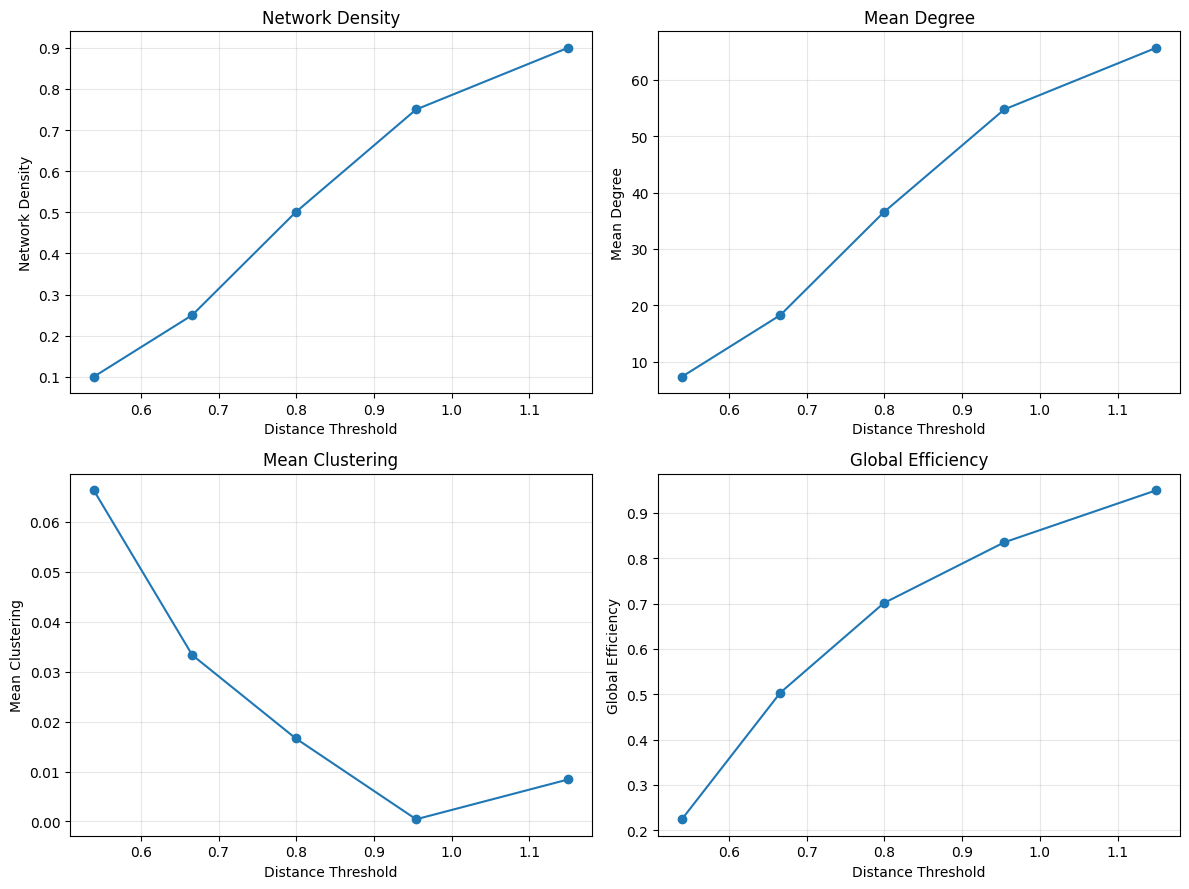

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

metrics_to_plot = [
    ("density", "Network Density"),
    ("mean_degree", "Mean Degree"),
    ("mean_clustering", "Mean Clustering"),
    ("global_efficiency", "Global Efficiency")
]

for ax, (column, title) in zip(axes.flat, metrics_to_plot):

    ax.plot(
        network_df["threshold"],
        network_df[column],
        marker="o"
    )

    ax.set_title(title)
    ax.set_xlabel("Distance Threshold")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    results_dir / "milestone9_network_characteristics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
interpretation = {
    "network_density": {
        "minimum": float(network_df["density"].min()),
        "maximum": float(network_df["density"].max())
    },
    "mean_degree": {
        "minimum": float(network_df["mean_degree"].min()),
        "maximum": float(network_df["mean_degree"].max())
    },
    "mean_clustering": {
        "minimum": float(network_df["mean_clustering"].min()),
        "maximum": float(network_df["mean_clustering"].max())
    },
    "global_efficiency": {
        "minimum": float(network_df["global_efficiency"].min()),
        "maximum": float(network_df["global_efficiency"].max())
    },
    "H0_intervals": len(H0),
    "H1_intervals": len(H1),
    "analysis_scope": "Single-participant exploratory analysis",
    "interpretation_status": "Descriptive, not clinical"
}

with open(
    results_dir / "milestone9_interpretation.json",
    "w"
) as f:

    json.dump(interpretation, f, indent=4)

print(json.dumps(interpretation, indent=4))

{
    "network_density": {
        "minimum": 0.10033320992225102,
        "maximum": 0.9000370233246946
    },
    "mean_degree": {
        "minimum": 7.324324324324325,
        "maximum": 65.70270270270271
    },
    "mean_clustering": {
        "minimum": 0.00044107010720050276,
        "maximum": 0.06632512473759614
    },
    "global_efficiency": {
        "minimum": 0.22415889470683992,
        "maximum": 0.9498951005800322
    },
    "H0_intervals": 74,
    "H1_intervals": 18,
    "analysis_scope": "Single-participant exploratory analysis",
    "interpretation_status": "Descriptive, not clinical"
}


In [17]:
network_df.to_csv(
    results_dir / "milestone9_network_metrics.csv",
    index=False
)

persistence_df.to_csv(
    results_dir / "milestone9_persistence_summary.csv",
    index=False
)

print("MILESTONE 9 COMPLETED")
print("All results saved in:", results_dir)

MILESTONE 9 COMPLETED
All results saved in: C:\Users\praja\functional-connectivity\neuroscience_project\results
